**Relevant reading for this problem set**:
<a href="https://moderndive.com/10-inference-for-regression.html"
target="_blank">ModernDive Chapter 10: Inference for Regression</a>.

## Background

For this problem set you will apply statistical inference to a linear
modeling and explore methods to check the required conditions. To start
we will build a model using data from the `palmerpenguins` package. The
`penguins` data contains size measurements for three penguin species
observed on three islands in the Palmer Archipelago, Antarctica.

First we will start with our typical exploratory data analysis and then
build our linear model. From there we will use our new skills to make
inferences about our regression model and check the necessary
conditions.

### Load packages

We will read the data in from the`palmerpenguins` package, explore the
data using the `dplyr` package and visualize it using the `ggplot2`
package. The `moderndive` package includes some nice functions to show
regression model outputs and finally use the `infer` package for “tidy”
and transparent statistical inference.

In [1]:
library('moderndive')
library('infer')
library('palmerpenguins')
library('tidymodels')


Attaching package: ‘palmerpenguins’


The following objects are masked from ‘package:datasets’:

    penguins, penguins_raw


── Attaching packages ────────────────────────────────────── tidymodels 1.4.1 ──

✔ broom        1.0.13     ✔ rsample      1.3.2 
✔ dials        1.4.4      ✔ tailor       0.1.0 
✔ dplyr        1.2.1      ✔ tidyr        1.3.2 
✔ ggplot2      4.0.3      ✔ tune         2.1.0 
✔ modeldata    1.5.1      ✔ workflows    1.3.0 
✔ parsnip      1.6.0      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
✔ recipes      1.3.3      

── Conflicts ───────────────────────────────────────── tidymodels_conflicts() ──
✖ purrr::discard() masks scales::discard()
✖ dplyr::filter()  masks stats::filter()
✖ dplyr::lag()     masks stats::lag()
✖ recipes::step()  masks stats::step()



### The data

In [2]:
pen = penguins |> 
  filter(!is.na(flipper_length_mm))

Take a moment to look at the data using `glimpse` and `head`. The dataset contains 8
variables. You can read more about the variables by placing your cursor in `penguins` and 
looking at the `Contextual Help` tool.

For our lab we will focus on four variables, the explanatory variables
include:

-   `flipper_length_mm` - an integer denoting flipper length
    (millimeters)
-   `bill_length_mm` - a number denoting bill length (millimeters)
-   `species`- denotes penguin species (Adélie, Chinstrap and Gentoo)

The outcome variable `body_mass_g` is an integer denoting body mass
(grams).

### Visualization

We will start by investigating the relationship between
‘flipper_length_mm’ and ‘body_mass_g’.

`geom_smooth()` using formula = 'y ~ x'


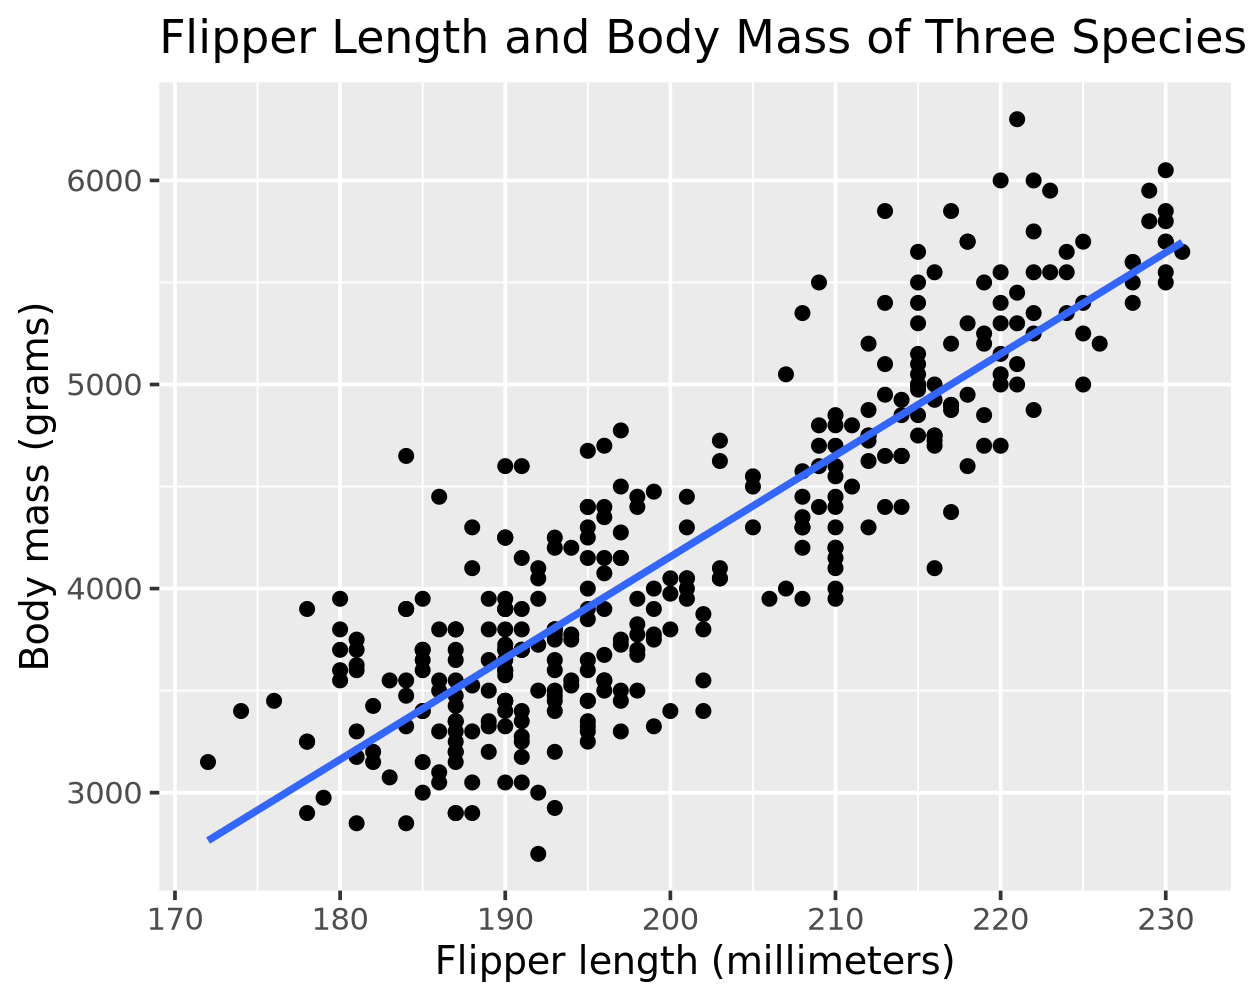

In [3]:
ggplot(data = pen, aes(y = body_mass_g, x = flipper_length_mm)) + 
  geom_point() + 
  geom_smooth(method = "lm", se = FALSE) +
  labs(x = "Flipper length (millimeters)", 
       y = "Body mass (grams)", 
       title = "Flipper Length and Body Mass of Three Species of Penguins") 

## Question 1

Does the relationship appear to be positive or negative? Does it look to
be reasonably linear?

**Answer:**

The relationship between flipper length and body mass is **positive**: penguins with longer flippers tend to weigh more. Body mass goes from about 3,000 g at flipper lengths near 175 mm to about 5,500–6,000 g at flipper lengths near 230 mm.

The relationship also looks **reasonably linear**. The points follow the fitted straight line closely across the whole range of flipper lengths, and they don't bend or curve away from it. The spread around the line stays fairly even, at about ±500 g. The points do seem to fall into two groups, one with shorter flippers and lower mass and one with longer flippers and higher mass, which is probably due to species differences. Even so, a single straight line describes the overall trend well.

## Create a linear regression model

Here we use the [standard error](https://moderndive.com/10-inference-for-regression.html#regression-se) to calculate a confidence interval. Later we will use the bootstrap resampling technique
that does not rely on distrubutional assumptions.

In [4]:
mod = linear_reg() |> set_engine('lm')

pen_model = mod |> fit(body_mass_g ~ flipper_length_mm, data = pen)

tidy(pen_model) |> mutate(lower_ci = estimate - 1.96 * std.error, upper_ci = estimate + 1.96 * std.error)

term,estimate,std.error,statistic,p.value,lower_ci,upper_ci
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),-5780.83136,305.814504,-18.90306,5.587301e-55,-6380.22779,-5181.43493
flipper_length_mm,49.68557,1.518404,32.72223,4.370681e-107,46.70949,52.66164


## Question 2

Using our shorthand interpretation for confidence intervals and the
regression table, write a sentence interpreting the 95% confidence
interval for $\beta_1$?

**Answer:**

We are **95% confident** that the true population slope $\beta_1$ is between **46.71 and 52.66**. In context, this means that for every 1 mm increase in flipper length, we are 95% confident that average body mass increases by somewhere between about **46.7 and 52.7 grams**.

The interval is entirely above 0, so it doesn't include the value 0. That means we have strong evidence of a real, positive linear relationship between flipper length and body mass. This matches the very small p-value ($4.37 \times 10^{-107}$).

## Question 3

Recall that the test statistic and $p$-value correspond to the
hypothesis test:

$$\begin{aligned} H_0:&\beta_{1} = 0 \\\ \mbox{vs }H_A:& \beta_{1} \neq 0 \end{aligned}$$

Write up the results & conclusions for this hypothesis test.

**Answer:**



**Results:** The estimated slope is $b_1 = 49.69$ with a standard error of $1.52$. That gives a test statistic of $t = 49.69 / 1.52 \approx 32.72$, with $n - 2 = 340$ degrees of freedom. The p-value is $4.37 \times 10^{-107}$, which is essentially 0.

**Conclusion:** The p-value is far below any usual significance level ($\alpha = 0.05$), so we **reject the null hypothesis** $H_0: \beta_1 = 0$ in favor of $H_A: \beta_1 \neq 0$. There is very strong evidence of a real linear relationship between flipper length and body mass in the population of penguins. The slope estimate is positive, so the relationship is positive: penguins with longer flippers tend to weigh more, about 50 g more on average for each extra millimeter of flipper length.

This agrees with the 95% confidence interval from Question 2, (46.71, 52.66), which doesn't include 0.



## Question 4

You may remember that this hypothesis test is only valid if certain
“conditions for inference for regression” are met. Let’s take a closer
look those conditions.

1.  Linearity of relationship between variables
2.  Independence of the residuals
3.  Normality of the residuals
4.  Equality of variance of the residuals

## Linearity of relationship between variables

**4a) ** This was analyzed in question 1. Did you say that the
relationship between `flipper_length_mm` and `body_mass_g` appears to be
linear?

**Answer:**



Yes. In Question 1, I said the relationship between `flipper_length_mm` and `body_mass_g` appears **reasonably linear**. In the scatterplot, the points follow the fitted straight line closely across the full range of flipper lengths (about 170–230 mm), and they don't curve or bend away from it. The points do seem to form two groups, which is probably due to species differences, but the overall trend is still well described by a straight line. So the **linearity condition is met**.



## Independence of the residuals

The observations in our data must be independent of one another. In this
data, we can not be sure this is case, for example, some of the penguins
included may be related (siblings, parents). We are not given enough
information to verify this condition has been met.

## Normality of the residuals

The third condition is that the residuals should follow a Normal
distribution centered 0. To check for normality, create a histogram.

The code to get the residuals is given.

In [6]:
regression_points = augment(pen_model, new_data = pen)

regression_points |> head()

.pred,.resid,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
<dbl>,<dbl>,<fct>,<fct>,<dbl>,<dbl>,<int>,<int>,<fct>
3212.256,537.743839,Adelie,Torgersen,39.1,18.7,181,3750,male
3460.684,339.316007,Adelie,Torgersen,39.5,17.4,186,3800,female
3907.854,-657.854091,Adelie,Torgersen,40.3,18.0,195,3250,female
3808.483,-358.482958,Adelie,Torgersen,36.7,19.3,193,3450,female
3659.426,-9.426259,Adelie,Torgersen,39.3,20.6,190,3650,male
3212.256,412.743839,Adelie,Torgersen,38.9,17.8,181,3625,female


**4b)**

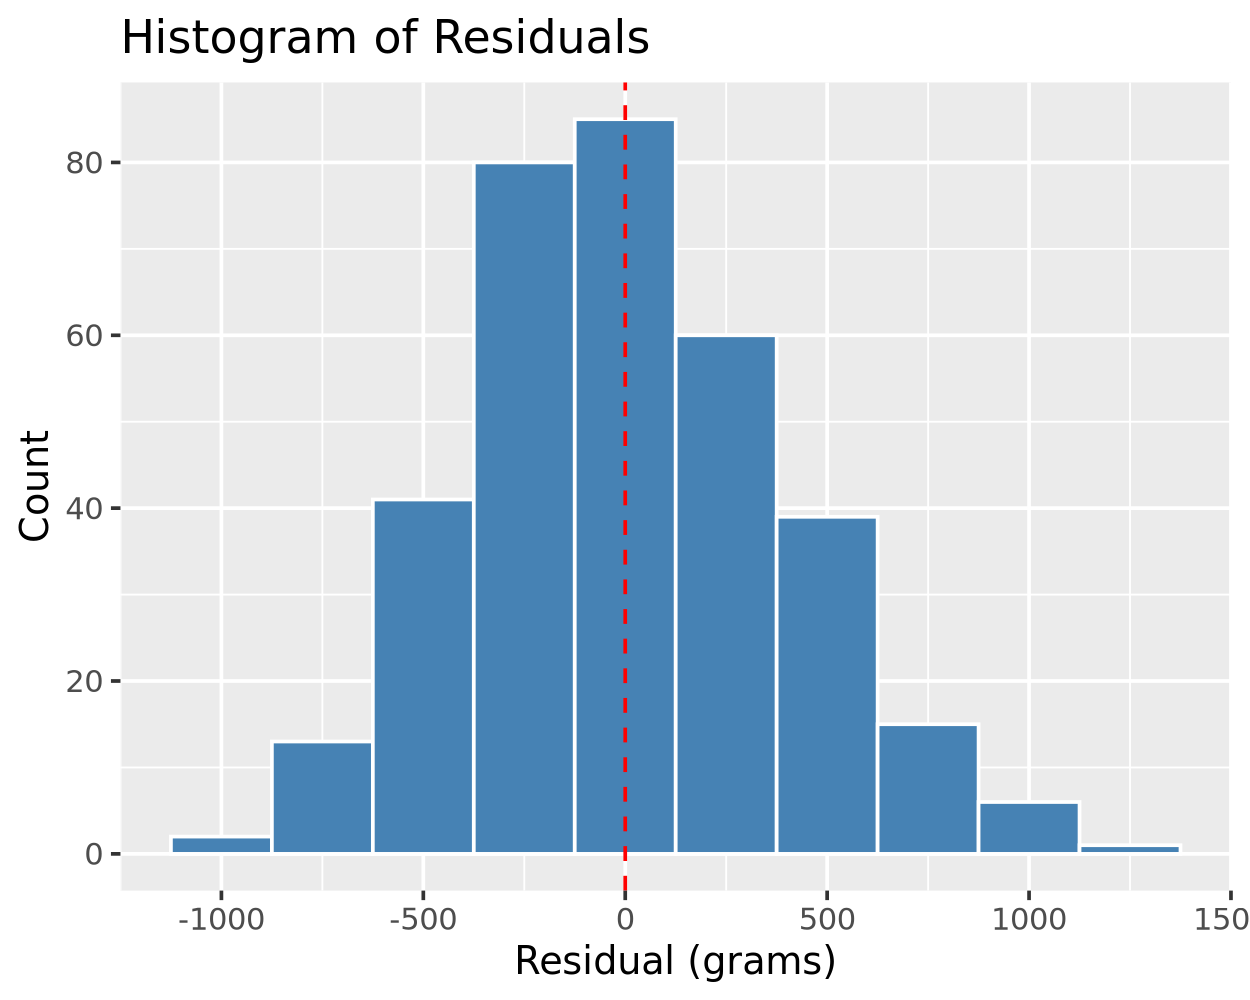

In [9]:
#Add code for the histogram.
ggplot(regression_points, aes(x = .resid)) +
  geom_histogram(binwidth = 250, color = "white", fill = "steelblue") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "red") +
  labs(x = "Residual (grams)",
       y = "Count",
       title = "Histogram of Residuals")



**4c)** Does this model meet the normality of residuals condition?

**Answer:**


Yes, the model reasonably meets the normality of residuals condition. The histogram of the residuals is **unimodal and roughly bell-shaped**, and it is **centered at about 0**: the tallest bars sit right around the red dashed line. Most residuals fall between about −750 and +750 grams, and the counts drop off fairly evenly in both directions.

There is a **slight right skew**. The right tail goes a little farther, out to about +1,250 g, than the left tail, which reaches about −1,000 g. There are also a few more residuals just below 0 than just above it. These departures are minor, though, and with a large sample ($n = 342$) they aren't a concern for inference. Overall, the residuals look approximately normal.



## Equality of variance of the residuals

The final condition says that the residual should exhibit equal variace
across all of the values of the explanatory variable.

To check this condition we can create a scatterplot that has our
explanatory variable, `flipper_length_mm`, on the x-axis and our
residuals on the y-axis. Does this model meet the Normality of Residuals
condition?

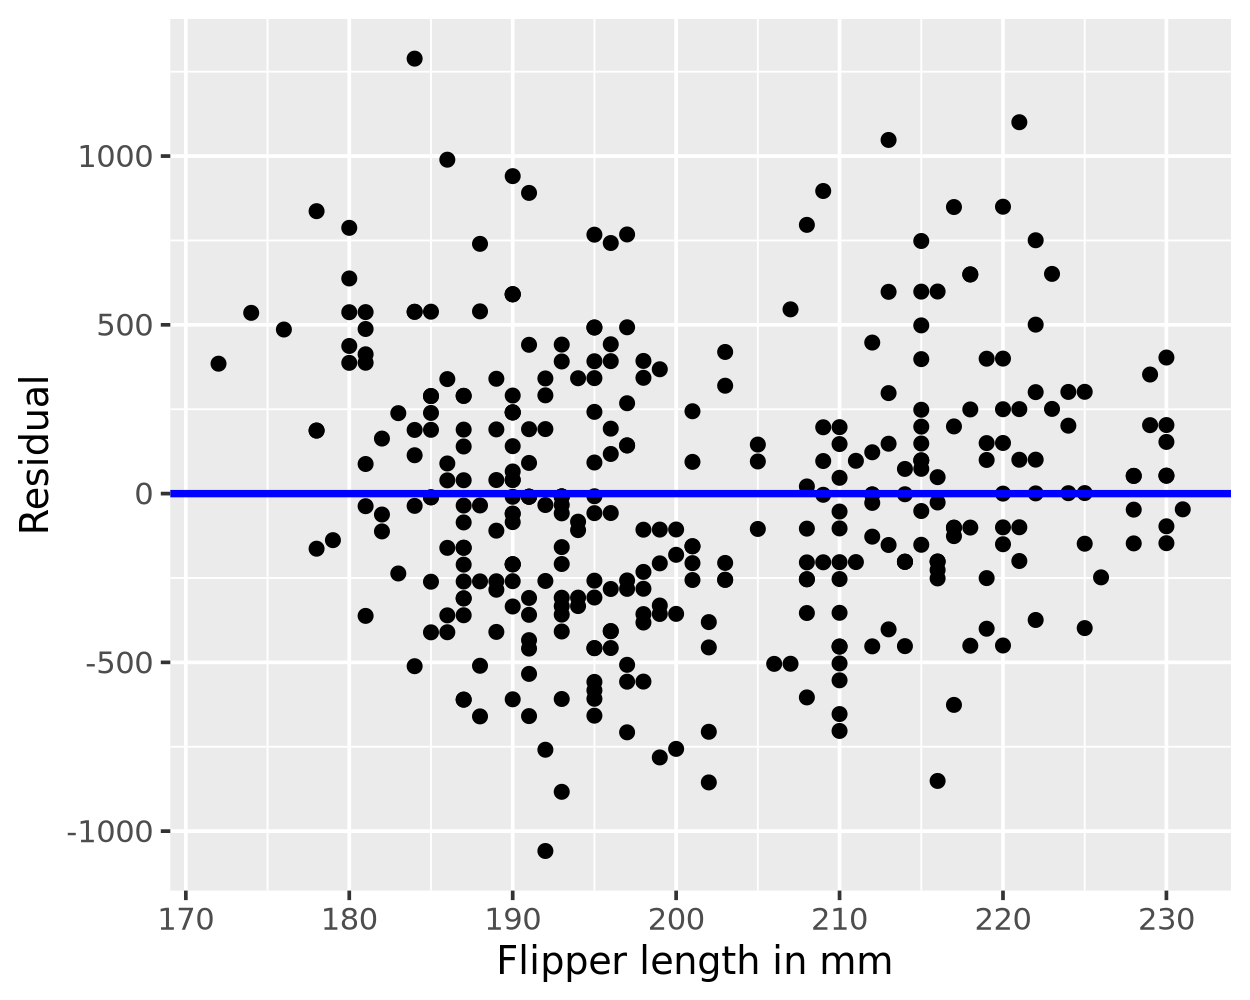

In [8]:
ggplot(regression_points, aes(x = flipper_length_mm, y = .resid)) +
  geom_point() +
  labs(x = "Flipper length in mm ", y = "Residual") +
  geom_hline(yintercept = 0, col = "blue", linewidth = 1)

**4d.** Does this model meet the equality of variance condition?

**Answer:**



Yes, the model reasonably meets the equality of variance condition. In the residual plot, the points are scattered fairly randomly above and below the horizontal line at 0. The vertical spread stays about the same, roughly −1,000 to +1,000 grams, across the full range of flipper lengths from about 170 to 230 mm. There's **no funnel or fan shape**: the spread doesn't clearly widen or narrow as flipper length increases. There's also no curved pattern, which further supports the linearity condition.

There are a few small irregularities. There's a gap in the data around 203–208 mm, which separates the two clusters (probably species groups), and there are fewer points at the very ends of the range, so the spread looks a bit narrower there. These come from having less data in those regions, not from a real change in variance, so the condition is met.



## Question 5

Now let’s circle back and take a second look at the confidence
intervals. Using this bootstrap distribution, we’ll construct the 95%
confidence interval using the percentile method and (if appropriate) the
standard error method as well. We can compare our results to the results
from R (which uses mathematical formula to construct confidence
intervals.)

### Step 1: Calculate the bootstrap statistic and Visualize the bootstrap distribution

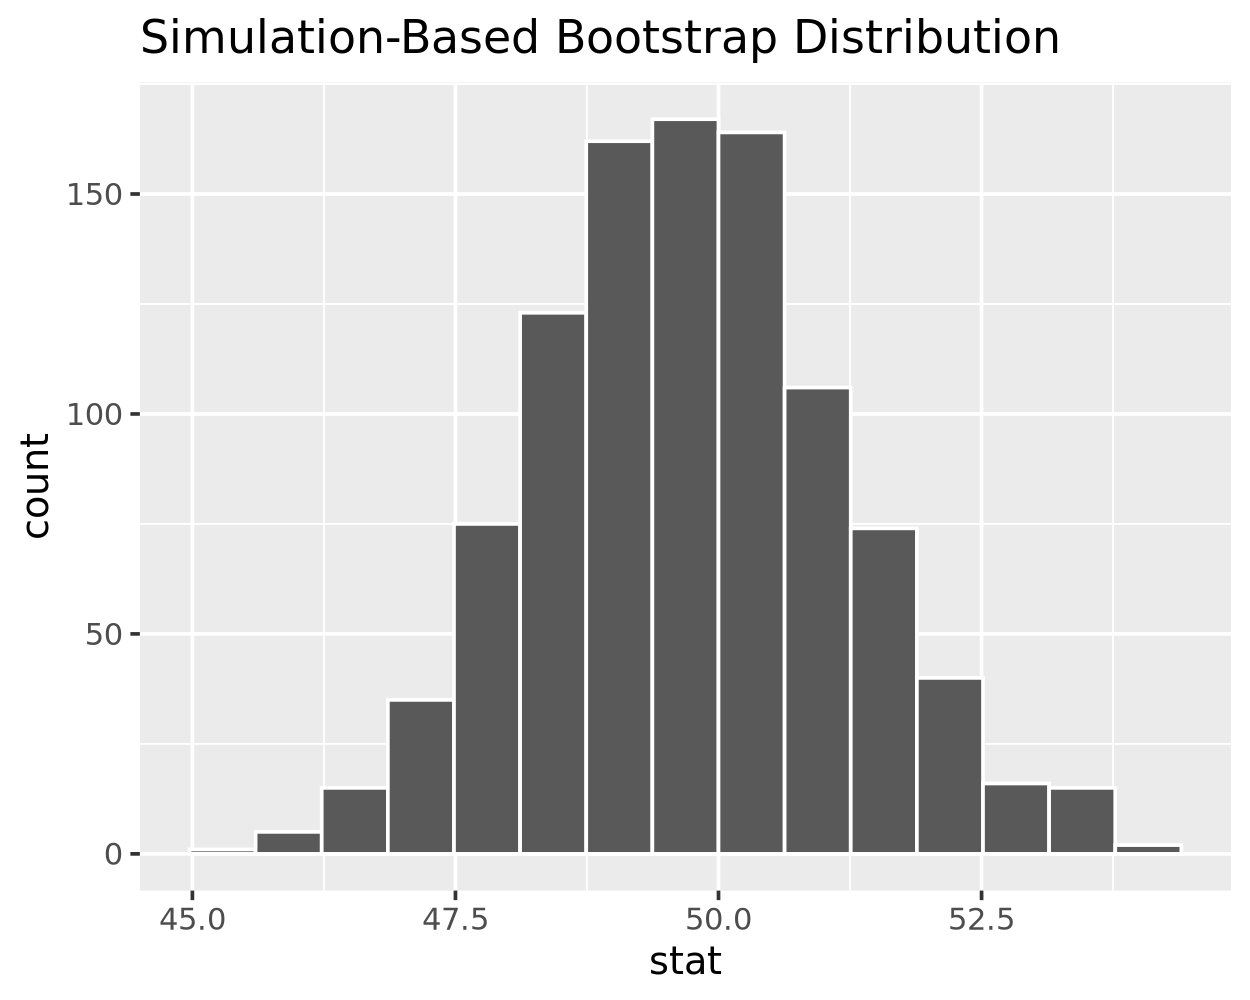

In [10]:
bootstrap_distn_slope = pen |> 
  specify(formula = body_mass_g ~ flipper_length_mm) |>
  generate(reps = 1000, type = "bootstrap") |>
  calculate(stat = "slope")

visualize(bootstrap_distn_slope)

### Step 2: Calculate CI from the a bootstap resample using the percentile method.

Find a 95% CI using percentile method:

In [11]:
#finish the code here:

bootstrap_distn_slope |>
    summarize(lower_ci = quantile(stat, 0.025), upper_ci = quantile(stat, 0.975))

lower_ci,upper_ci
<dbl>,<dbl>
47.04111,52.7005


## Question 6

Write down the two 95% confidence intervals for the $\beta_{1}$. a, b,
c, and d with the appropriate values you’ve computed.

When you are done, make sure all the `|` in the table still line up so
your results print out in a table!

| CI construction method                | lower value | upper value |
|---------------------------------------|-------------|-------------|
| Using bootstrap: percentile rule      | a           | b           |
| Using mathematical formula (see [above](#Create-a-linear-regression-model)) | c           | d           |

In your opinion, would you say these three confidence intervals are
similar?

**Answers:**



| CI construction method | lower value | upper value |
|:---|:---:|:---:|
| Using bootstrap: percentile rule | 47.04 | 52.70 |
| Using mathematical formula (see above) | 46.71 | 52.66 |

Yes, the confidence intervals are **very similar**. Both are centered near the observed slope of about 49.7, and their endpoints differ by less than 0.35 g/mm. The bootstrap percentile interval is slightly narrower (width ≈ 5.66) than the formula-based interval (width ≈ 5.95). That small difference comes from the randomness of bootstrap resampling, so a different set of 1,000 resamples would give slightly different endpoints.

Both intervals lead to the same conclusion: neither includes 0, so we are 95% confident that each extra millimeter of flipper length goes with about 47–53 g more body mass on average. The two methods agree closely because the conditions for inference were reasonably met and the bootstrap distribution was bell-shaped.



## Part 2

For the next part you will check the conditions for regression inference
for a new model. This model will have `bill_length_mm` and `species` as
explanatory variables, and we’ll use the parallel slopes model

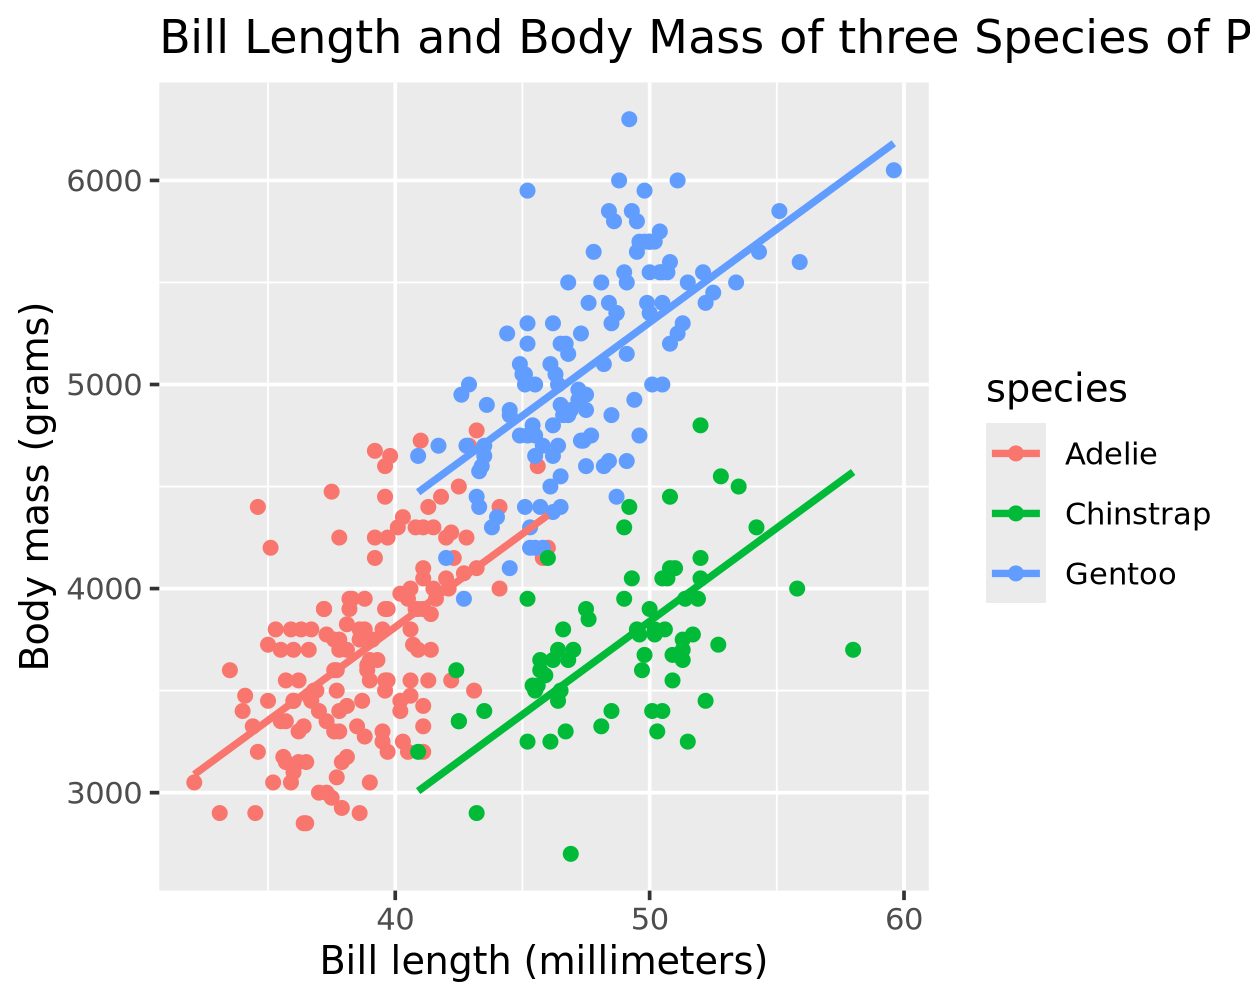

In [12]:
ggplot(data = pen, aes(y = body_mass_g, x = bill_length_mm, color=species)) + 
  geom_point() + 
  geom_parallel_slopes(se = FALSE) +
  labs(x = "Bill length (millimeters)", 
       y = "Body mass (grams)", 
       title = "Bill Length and Body Mass of three Species of Penguins") 

Let’s fit the parallel slopes model

In [13]:
# Fit regression model:

mod = linear_reg() |> set_engine('lm')

pen_parallel = mod |> fit(body_mass_g ~ bill_length_mm + species, data = pen)

# Get regression table:
tidy(pen_parallel)

term,estimate,std.error,statistic,p.value
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
(Intercept),153.73969,268.901233,0.5717329,5.678829e-01
bill_length_mm,91.43582,6.887119,13.2763517,1.158990e-32
speciesChinstrap,-885.81208,88.250154,-10.0375131,6.373927e-21
speciesGentoo,578.62916,75.362341,7.6779617,1.756354e-13


Let us once again inspect the conditions necessary for inference with
regression.

1.  Linearity of relationship between variables
2.  Independence of the residuals
3.  Normality of the residuals
4.  Equality of variance of the residuals

## Question 7

**Check for Linearity of relationship between variables **

Would you say that the relationship between `bill_length_mm` and
`body_mass_g` appears to be linear for each species?

**Answer:**

**Answer:**

Yes, the relationship between `bill_length_mm` and `body_mass_g` appears **reasonably linear for each species**. In the scatterplot colored by species, each group's points follow a positive, roughly straight-line trend, and none of the groups shows a clear curve or bend.

- **Adelie (red):** a positive linear trend with fairly wide scatter around the line, so the relationship is moderate.
- **Gentoo (blue):** a clear, fairly strong positive linear trend. The points follow the line closely across bill lengths of about 41–60 mm.
- **Chinstrap (green):** a positive linear trend, but weaker and more scattered than the other two. A few points sit far from the line, for example one at about 58 mm / 3,700 g and one at about 47 mm / 2,700 g.

So the linearity condition is met within each species. However, the parallel slopes model forces all three lines to have the same slope. Chinstrap in particular may have a somewhat flatter true slope, so an interaction model could fit that group slightly better.



**Check for Independence of the residuals **

This is the same as the first model that we looked it. The observations
in our data must be independent of one another. In this data, we can not
be sure this is case, for example, some of the penguins included may be
related (siblings, parents). We are not given enough information to
verify this condition has been met.

## Question 8

Check Normality of the residuals (and they should be centered at 0.)

**8a) **

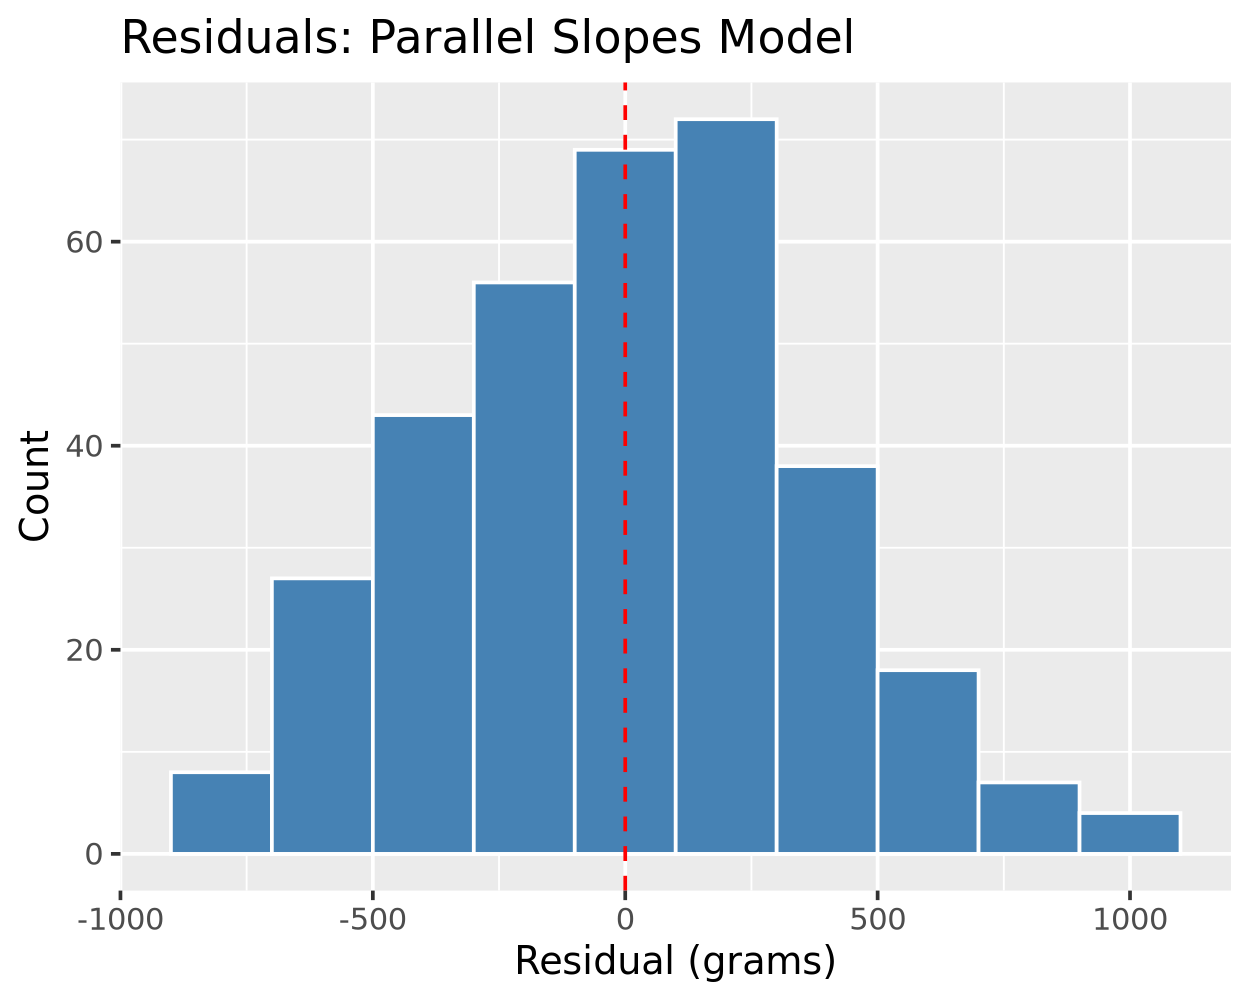

In [14]:
#Add code for the histogram:
regression_points_2 = augment(pen_parallel, new_data = pen)

ggplot(regression_points_2, aes(x = .resid)) +
  geom_histogram(binwidth = 200, color = "white", fill = "steelblue") +
  geom_vline(xintercept = 0, linetype = "dashed", color = "red") +
  labs(x = "Residual (grams)",
       y = "Count",
       title = "Residuals: Parallel Slopes Model")



**8b)** Does this model meet the Normality of Residuals condition?

**Answer:**



Yes, the parallel slopes model meets the normality of residuals condition. The histogram of the residuals is **unimodal, roughly bell-shaped, and centered at about 0**: the two tallest bars sit on either side of the red dashed line at 0. The residuals range from about −900 to +1,100 grams, and most fall between about −500 and +500 grams. The counts taper off fairly evenly in both directions.

The distribution is **approximately symmetric**. The right tail reaches slightly farther (to about +1,100 g) than the left (to about −900 g), but the difference is small. There are no extreme outliers or gaps. With a large sample ($n = 342$), these minor departures from perfect normality aren't a concern, so the condition is reasonably met.



## Question 9

Check for Equality of variance of the residuals

To check this condition we can create a scatterplot that has our
explanatory variable, `flipper_length_mm`, on the x-axis and our
residuals on the y-axis.

**9a)**

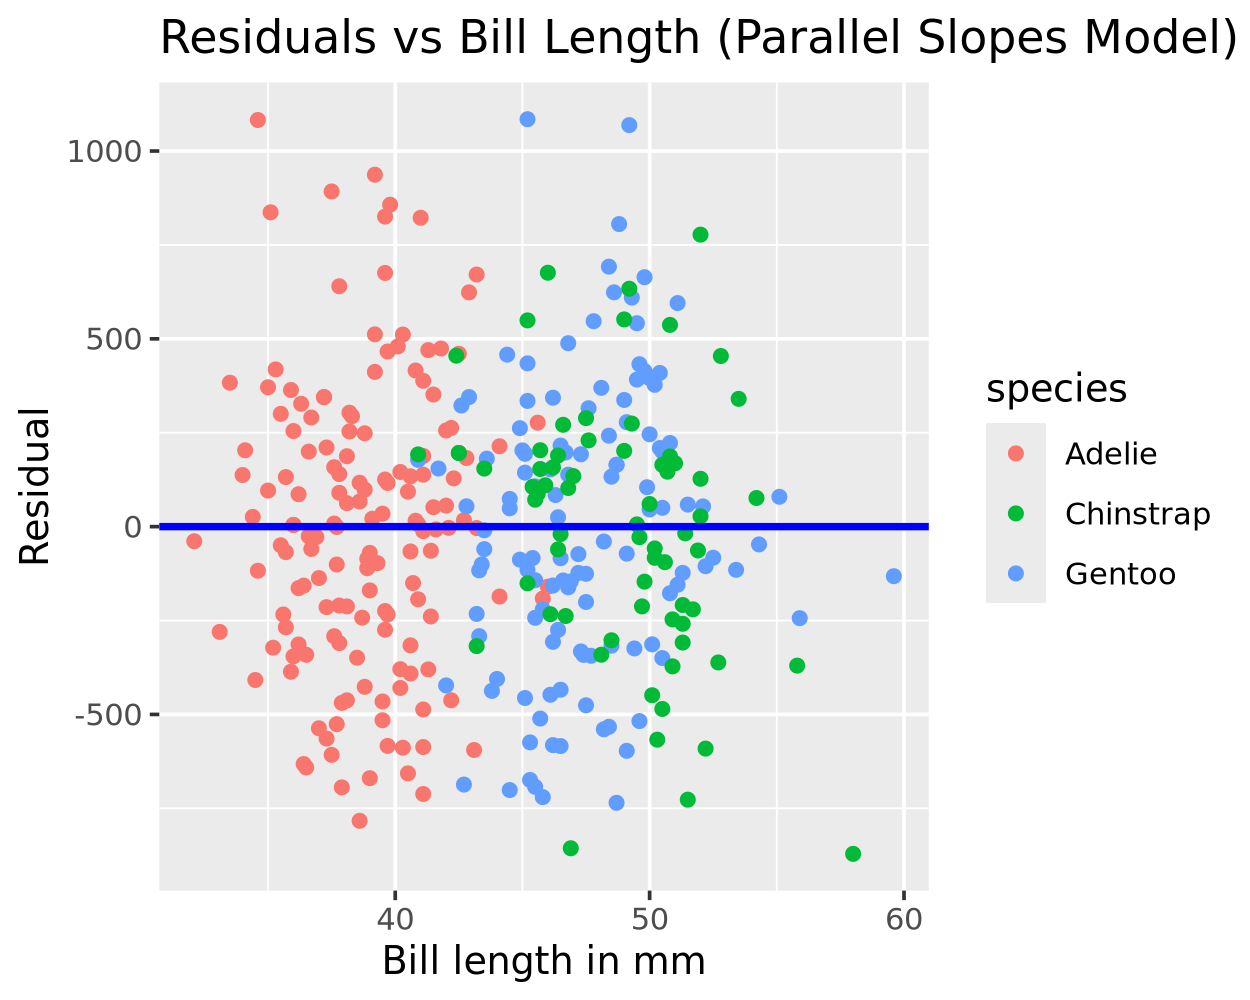

In [15]:
#Add code to check this condition:
ggplot(regression_points_2, aes(x = bill_length_mm, y = .resid, color = species)) +
  geom_point() +
  geom_hline(yintercept = 0, col = "blue", linewidth = 1) +
  labs(x = "Bill length in mm", y = "Residual",
       title = "Residuals vs Bill Length (Parallel Slopes Model)")



**9b) **Does this meet the equality of variance of the residuals
condition?

**Answer:**



Yes, the parallel slopes model reasonably meets the equality of variance condition. In the plot of residuals against `bill_length_mm`, the points are scattered randomly above and below the horizontal line at 0. The vertical spread stays about the same, roughly −800 to +1,000 grams, across the whole range of bill lengths from about 32 to 60 mm. There's **no funnel or fan shape**: the spread doesn't



## Question 10

Run the code below to find the confidence intervals for our model's coefficients.

In [16]:
boots = bootstraps(pen, times = 1000, apparent = TRUE)

mod = linear_reg() |> set_engine('lm')

boot_models  = boots |> 
  mutate(model = map(splits, ~mod |> fit(body_mass_g ~ bill_length_mm + species, data = as_tibble(.x))),
         coef_info = map(model, tidy))

boot_coefs = boot_models |> 
  unnest(coef_info)

percentile_intervals = int_pctl(boot_models, coef_info)

percentile_intervals

term,.lower,.estimate,.upper,.alpha,.method
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
(Intercept),-350.35583,131.3543,611.4815,0.05,percentile
bill_length_mm,79.46212,92.0306,104.3923,0.05,percentile
speciesChinstrap,-1047.69174,-894.7925,-744.2346,0.05,percentile
speciesGentoo,433.55335,573.1162,718.1332,0.05,percentile


`stat_bin()` using `bins = 30`. Pick better value `binwidth`.


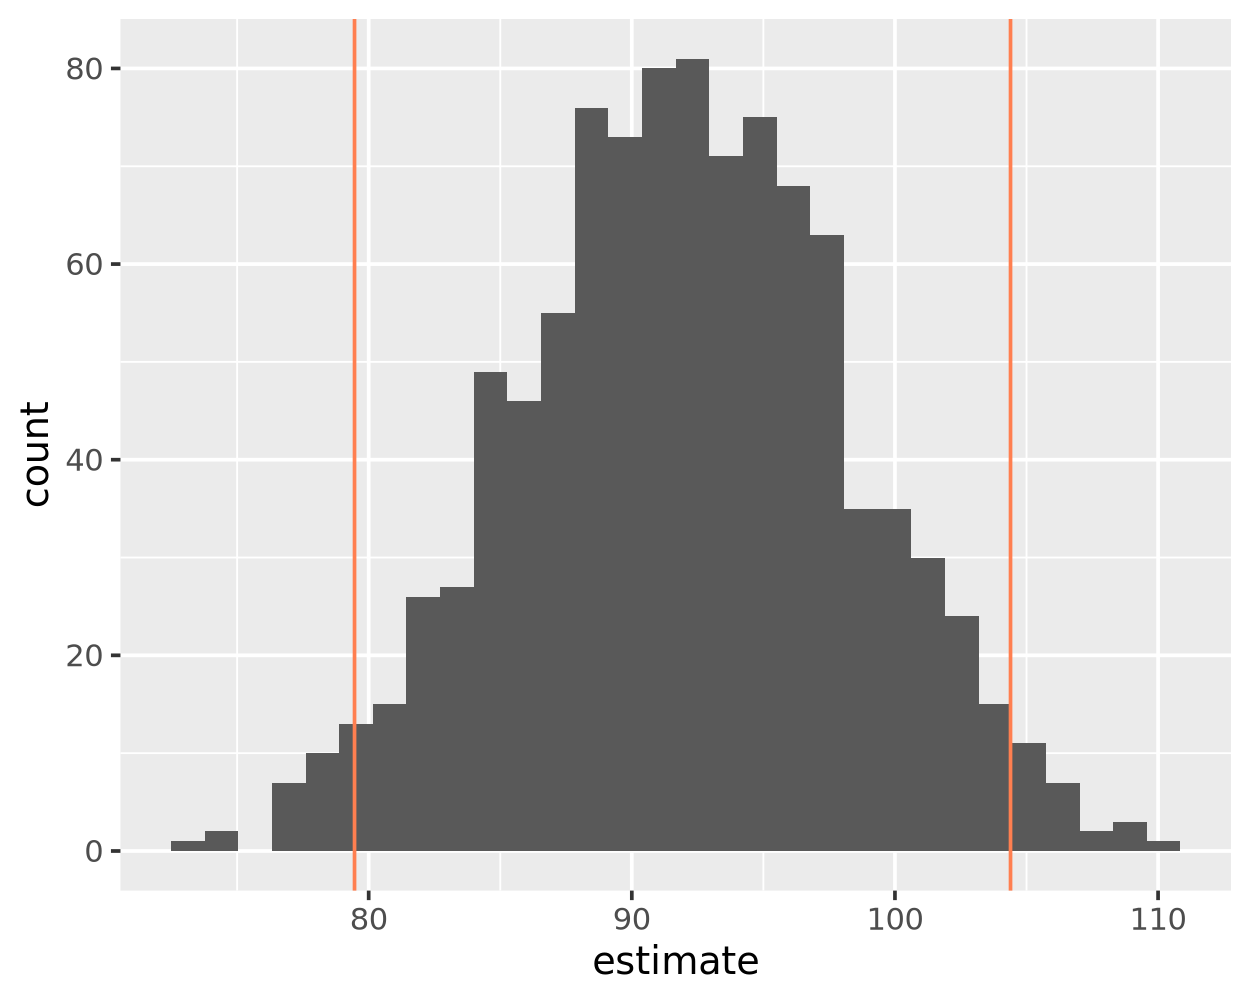

In [17]:
boot_coefs |> 
    filter(term == 'bill_length_mm') |>
ggplot(aes(x = estimate)) +
    geom_histogram() +
    geom_vline(xintercept = percentile_intervals |> filter(term == 'bill_length_mm') |> pull(.lower), color = 'coral') +
    geom_vline(xintercept = percentile_intervals |> filter(term == 'bill_length_mm') |> pull(.upper), color = 'coral')

What can we conclude about the relationship between bill length and body
mass?

**Answer:**



There is a **positive relationship** between bill length and body mass, even after accounting for species. The bootstrap 95% percentile confidence interval for the `bill_length_mm` coefficient is **(79.46, 104.39)**, with a point estimate of about 92.03. **Holding species constant**, we are 95% confident that each 1 mm increase in bill length goes with an average increase in body mass of about **79.5 to 104.4 grams**.

The interval is entirely above 0, so it doesn't include 0. That gives strong evidence that the true slope $\beta_1$ is not zero: bill length is a meaningful predictor of body mass within each species. The histogram of the 1,000 bootstrap slope estimates is roughly bell-shaped and centered near 92, with the coral lines marking the interval endpoints. This supports the conclusion that the estimate is stable.

The species terms also matter. Compared with Adelie penguins that have the same bill length, Chinstrap penguins weigh about **744–1,048 g less** and Gentoo penguins weigh about **434–718 g more**. Neither interval includes 0, so species has a significant effect on body mass in addition to bill length.

